# 11 · From Itemsets to Cross-sell and Upsell

Turn the trained model's scores into the two features a shop asks for first — **cross-sell** (what else goes with
this basket?) and **upsell** (which variant will the shopper pick?) — and compare against plain **counting**.

The model gives log P(item | basket) for every item: a conditional-probability machine for any basket. Lift divides
out how popular the item is anyway.

**CPU notes and reductions (to save time).** The score table and the no-basket row come from the section 9
background job; everything after that is the package's plain numpy code (`thilimarketbasket.recommend`), unchanged.
- **Model:** my 100-step checkpoint (course: 800 steps), so it has seen an eighth of the course's baskets.
- **Test: the first 50 of the 200 cases** (course: 200), the same 50 as section 9. *Every* method here — popularity,
  counting, counting-lift and the model at each alpha — is scored on those same 50 cases, so the comparison is fair.

**The results are noisy because of the small sizes.** With 50 cases one case moves an MRR by up to 0.02, the
"completes a planted set" group has only a handful of cases, and the bootstrap ranges are wide. Small gaps between
methods (e.g. model vs counting) can't be told apart from noise here.

In [1]:
import json
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from thilimarketbasket.dataset import generate_dataset
from thilimarketbasket.evaluate import candidate_token_ids, make_cases, popularity_scores, rank_of
from thilimarketbasket.recommend import ItemToItem, lift_adjusted, rank_among, repeat_share, top_k, variants_of
from thilimarketbasket.verbalize import verbalize_prefix
from mybasket.score import load, score_candidates

torch.set_num_threads(20)
data = generate_dataset(n_baskets=100_000, seed=0)
catalog = data.catalog
names = [item.name for item in catalog]
position = {name: i for i, name in enumerate(names)}

is_val = np.random.default_rng(0).random(len(data.baskets)) < 0.05      # the split from section 7
train = [b for b, v in zip(data.baskets, is_val) if not v]
val = [b for b, v in zip(data.baskets, is_val) if v]
N_CASES = 50                                                               # course: 200 (reduced to save time)
cases = make_cases(val, names, n_cases=200, seed=0)[:N_CASES]             # the first 50 of sections 8's cases, as in section 9

STEPS, BATCH = 100, 16                                                     # my section 9 run (course: 800 x 16, reduced to save time)
CHECKPOINT = Path("checkpoints") / f"baskets-{STEPS}x{BATCH}"
model, tokenizer = load(str(CHECKPOINT))
candidates = candidate_token_ids(tokenizer, names)

SCORES, BLANK = CHECKPOINT / f"scores-{N_CASES}.npy", CHECKPOINT / "scores-blank.npy"
if SCORES.exists():
    scores, blank = np.load(SCORES), np.load(BLANK)
    print("reusing the saved scores", scores.shape)
else:
    started = time.time()
    blank = score_candidates(model, tokenizer.encode("Basket:"), candidates)
    scores = np.stack([score_candidates(model, tokenizer.encode(verbalize_prefix(c["visible"], seed=k)), candidates)
                       for k, c in enumerate(cases)])
    np.save(SCORES, scores); np.save(BLANK, blank)
    print(f"scored {len(cases)} cases in {(time.time() - started) / 60:.0f} minutes", scores.shape)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  28%|██▊       | 77/272 [00:00<00:00, 761.54it/s]

Loading weights:  57%|█████▋    | 154/272 [00:00<00:00, 696.70it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1227.71it/s]

reusing the saved scores (50, 1000)


In [2]:
case = cases[0]
start = time.time()
score_candidates(model, tokenizer.encode(verbalize_prefix(case["visible"], seed=0)), candidates)
print(f"scoring one basket against all {len(names):,} items: {time.time() - start:.1f} seconds")

scoring one basket against all 1,000 items: 32.0 seconds


Seconds per basket — far too slow for a checkout page as written (the course's M3 GPU took ~2.3 s; this CPU is slower).

## Two baskets and four suggestion lists

raw = highest log P(item | basket); alpha 0.25 = subtract a quarter of the no-basket score; lift = subtract all of
it; counting = no language model. Popularity rank in brackets (1 = best seller).

In [3]:
counting = ItemToItem(train, names)
by_popularity = np.argsort(-popularity_scores(train, names))
popularity_rank = np.empty(len(names), dtype=int)
popularity_rank[by_popularity] = np.arange(1, len(names) + 1)

sets = [set(p.items) for p in data.planted]
def completes_a_planted_set(case):
    everything = set(case["visible"]) | {case["target"]}
    return any(case["target"] in s and s <= everything for s in sets)
completes = np.array([completes_a_planted_set(c) for c in cases])

def show(k):
    case = cases[k]
    inside = [position[v] for v in case["visible"]]
    print(f"case {k}: the basket holds {len(inside)} items; the hidden item is {case['target']!r}"
          f" (popularity rank {popularity_rank[position[case['target']]]})")
    lists = {"raw": scores[k], "alpha 0.25": lift_adjusted(scores[k], blank, 0.25),
             "lift": lift_adjusted(scores[k], blank, 1.0), "counting": counting.score(case["visible"])}
    for label, s in lists.items():
        print(f"  {label:<11}", "; ".join(f"{names[j]} ({popularity_rank[j]})" for j in top_k(s, 5, inside)))
    print()

show(int(np.flatnonzero(completes)[0]))
show(int(np.flatnonzero(~completes)[0]))

case 4: the basket holds 16 items; the hidden item is 'Crunch Club Murukku Rs 10 pack' (popularity rank 31)
  raw         Crunchy Crust Bread 400 g (2); Tomato 1 kg (11); Golden Drop Sunflower Oil 500 ml (3); Surya Grains Wheat Flour (Atta) 1 kg (9); Coriander Leaves bunch (12)
  alpha 0.25  Crunchy Crust Bread 400 g (2); Kids Korner Notebook pack of 5 (10); Tomato 1 kg (11); Coriander Leaves bunch (12); Surya Grains Wheat Flour (Atta) 1 kg (9)
  lift        Kids Korner Baby Wipes pack of 72 (1000); Pragati Besan 5 kg (966); Pragati Besan 1 kg (716); Little Lotus Baby Wipes pack of 72 (740); Pragati Jaggery 1 kg (794)
  counting    Crunch Club Murukku Rs 10 pack (31); Crunchy Crust Bread 400 g (2); Golden Drop Sunflower Oil 500 ml (3); Potato 1 kg (8); Chai Chaska Sugar 1 kg (7)

case 0: the basket holds 12 items; the hidden item is 'Nandini Pure Eggs 12 pack' (popularity rank 137)
  raw         Crunchy Crust Bread 400 g (2); Ginger 500 g (5); Tomato 1 kg (11); Coriander Leaves bunch (

The most likely next items are the shop's best sellers — right, but nobody needs telling. Pure lift swings to the
far tail. That's the central cross-sell problem, and it isn't a modelling problem.

## Measuring a list, and the alpha dial

score = log P(item | basket) − alpha · log P(item | no basket). Measures: MRR, hits, median popularity rank of the
top 5 (novelty), and share of top-5 suggestions that repeat a product already in the basket (should be ~0).

In [4]:
def evaluate(score_for_case):
    """MRR, hits, the popularity rank of the top five, and the share of repeated products, for one way of scoring."""
    ranks, popularity, repeats = [], [], []
    for k, case in enumerate(cases):
        s = score_for_case(k, case)
        inside = [position[v] for v in case["visible"]]
        ranks.append(rank_of(s, position[case["target"]], inside))
        best = top_k(s, 5, inside)
        popularity.extend(popularity_rank[best])
        repeats.append(repeat_share(best, inside, catalog))
    r = np.asarray(ranks)
    return {"MRR": np.mean(1 / r), "hits@1": np.mean(r <= 1), "hits@10": np.mean(r <= 10),
            "median popularity rank of the top 5": float(np.median(popularity)), "repeats in the top 5": np.mean(repeats)}

dial = {f"model, alpha {a}": evaluate(lambda k, c, a=a: lift_adjusted(scores[k], blank, a)) for a in (0, 0.25, 0.5, 0.75, 1.0)}
pd.DataFrame(dial).T.round(3)

,MRR,hits@1,hits@10,median popularity rank of the top 5,repeats in the top 5
"model, alpha 0",0.080,0.04,0.16,4.0,0.072
"model, alpha 0.25",0.071,0.02,0.16,4.0,0.056
"model, alpha 0.5",0.048,0.00,0.14,5.0,0.044
"model, alpha 0.75",0.014,0.00,0.00,476.0,0.020
"model, alpha 1.0",0.004,0.00,0.00,949.0,0.028


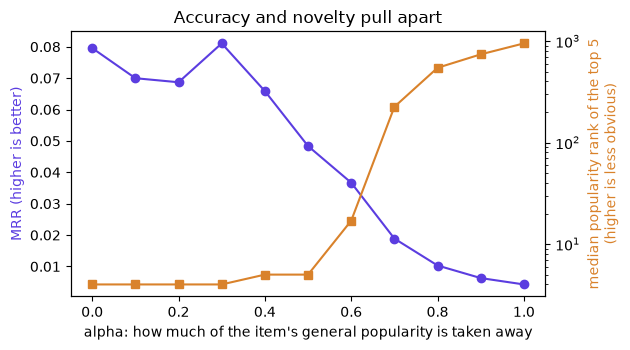

In [5]:
alphas = np.linspace(0, 1, 11)
results = [evaluate(lambda k, c, a=a: lift_adjusted(scores[k], blank, a)) for a in alphas]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(alphas, [r["MRR"] for r in results], color="#5b3de0", marker="o")
ax.set_xlabel("alpha: how much of the item's general popularity is taken away")
ax.set_ylabel("MRR (higher is better)", color="#5b3de0")
twin = ax.twinx()
twin.plot(alphas, [r["median popularity rank of the top 5"] for r in results], color="#d9822b", marker="s")
twin.set_yscale("log")
twin.set_ylabel("median popularity rank of the top 5\n(higher is less obvious)", color="#d9822b")
ax.set_title("Accuracy and novelty pull apart")
plt.tight_layout()
plt.show()

## A fair comparison: just count

Item-to-item counting ("customers who bought X also bought Y"): average P(other | item) over the basket's items.

In [6]:
table = {"popularity (ignores the basket)": evaluate(lambda k, c: popularity_scores(train, names)),
         "counting": evaluate(lambda k, c: counting.score(c["visible"])),
         "counting, lift": evaluate(lambda k, c: counting.score(c["visible"], lift=True)),
         "model, alpha 0": dial["model, alpha 0"],
         "model, alpha 0.25": dial["model, alpha 0.25"],
         "model, alpha 1 (lift)": dial["model, alpha 1.0"]}
pd.DataFrame(table).T.round(3)

,MRR,hits@1,hits@10,median popularity rank of the top 5,repeats in the top 5
popularity (ignores the basket),0.042,0.00,0.12,3.0,0.080
counting,0.233,0.22,0.22,4.0,0.060
"counting, lift",0.149,0.12,0.22,938.0,0.020
"model, alpha 0",0.080,0.04,0.16,4.0,0.072
"model, alpha 0.25",0.071,0.02,0.16,4.0,0.056
"model, alpha 1 (lift)",0.004,0.00,0.00,949.0,0.028


In [7]:
def gap_range(a, b, draws=2000, seed=0):
    rng = np.random.default_rng(seed)
    d = np.asarray(a) - np.asarray(b)
    means = [rng.choice(d, size=len(d)).mean() for _ in range(draws)]
    return d.mean(), np.percentile(means, [2.5, 97.5])

def reciprocal_ranks(score_for_case):
    return np.array([1 / rank_of(score_for_case(k, c), position[c["target"]], [position[v] for v in c["visible"]])
                     for k, c in enumerate(cases)])

model_rr = reciprocal_ranks(lambda k, c: scores[k])
counting_rr = reciprocal_ranks(lambda k, c: counting.score(c["visible"]))
mean, (low, high) = gap_range(model_rr, counting_rr)
print(f"model minus counting, case by case: {mean:+.3f}   (95% range {low:+.3f} to {high:+.3f})")

for label, chosen in (("hidden item completes a planted set", completes), ("it does not", ~completes)):
    print(f"{label:<36} cases {chosen.sum():>3}   model MRR {model_rr[chosen].mean():.3f}   counting MRR {counting_rr[chosen].mean():.3f}")

model minus counting, case by case: -0.154   (95% range -0.254 to -0.063)
hidden item completes a planted set  cases  12   model MRR 0.249   counting MRR 0.924
it does not                          cases  38   model MRR 0.026   counting MRR 0.015


## Upsell: which variant will the shopper choose?

Rank the hidden SKU only among the other brands/sizes of the same product.

In [8]:
groups = variants_of(catalog)
popularity = popularity_scores(train, names)
tested = [(k, position[c["target"]], groups[catalog[position[c["target"]]].base]) for k, c in enumerate(cases)
          if len(groups[catalog[position[c["target"]]].base]) > 1]

def variant_mrr(score_for_case):
    ranks = np.array([rank_among(score_for_case(k), target, group) for k, target, group in tested])
    return np.mean(1 / ranks), np.mean(ranks == 1)

random_mrr = np.mean([np.mean(1 / np.arange(1, len(group) + 1)) for _, _, group in tested])
print(f"{len(tested)} of the {len(cases)} cases hide an item that has other variants; "
      f"{np.mean([len(g) for _, _, g in tested]):.1f} variants per product on average")
pd.DataFrame({"random": {"MRR among the variants": random_mrr},
              "popularity": dict(zip(["MRR among the variants", "picks the right one"], variant_mrr(lambda k: popularity))),
              "model": dict(zip(["MRR among the variants", "picks the right one"], variant_mrr(lambda k: scores[k])))}).round(3)

49 of the 50 cases hide an item that has other variants; 8.2 variants per product on average


,random,popularity,model
MRR among the variants,0.365,0.596,0.663
picks the right one,NaN,0.408,0.510


The generator picks each variant from its popularity regardless of the rest of the basket, so there's nothing for
the basket to teach here — the model can only learn which variants are popular. (Here the model scores a little
above popularity, but on only ~49 cases that gap is well within noise; the course, with 190 cases, found them equal.)

## Try it: a counting shortlist re-ranked by the model

Keep counting's top 50, re-rank only those with the model's scores (the fast-enough-for-checkout shortcut).

In [9]:
def shortlist(k, c, size=50):
    count = counting.score(c["visible"])
    inside = [position[v] for v in c["visible"]]
    keep = top_k(count, size, inside)
    s = np.full(len(names), -np.inf)
    s[keep] = scores[k][keep]
    return s

print("model on its own:          ", {k: round(float(v), 3) for k, v in evaluate(lambda k, c: scores[k]).items()})
print("counting top-50, re-ranked:", {k: round(float(v), 3) for k, v in evaluate(shortlist).items()})

model on its own:           {'MRR': 0.08, 'hits@1': 0.04, 'hits@10': 0.16, 'median popularity rank of the top 5': 4.0, 'repeats in the top 5': 0.072}


counting top-50, re-ranked: {'MRR': 0.076, 'hits@1': 0.04, 'hits@10': 0.18, 'median popularity rank of the top 5': 4.0, 'repeats in the top 5': 0.072}


## What I changed from the course (no Mac), and every reduction

- The only model-dependent input is the score table; it comes from my PyTorch scorer (`work/mybasket/score.py`) on my
  100-step checkpoint. All the cross-sell / upsell code is the package's `recommend` module, unchanged.
- **Reductions (to save time):** model trained 100 steps (course 800); every method compared on the first 50 of the
  200 test cases (course 200), the same 50 as section 9.
- **Noisy:** with 50 cases, gaps of a few hundredths in MRR are within noise, and the "completes a planted set" group
  is only a handful of cases.
- Added a small "Try it" from the course's list: a counting shortlist re-ranked by the model.

## Test yourself

**1. Why is a list sorted purely by P(item | basket) not a good cross-sell list?**
The most likely next items are the shop's best sellers, which go into almost every basket. They're probably right,
but the shopper buys them anyway, so suggesting them adds nothing.

**2. What does the alpha dial trade off?**
alpha 0 gives the most likely items (accurate but obvious); alpha 1 gives pure lift, items the basket makes more
likely than usual, which drifts to rare, noisy items and loses accuracy. In between mixes the two; the setting is a
business choice, best tested on real customers.

**3. Why is item-to-item counting such a strong baseline on this data?**
The planted patterns are fixed itemsets, so counting which items share baskets finds them directly, with no training.
In my run counting is clearly better than my 100-step model (MRR 0.233 vs 0.080, and the case-by-case gap's range
stays below zero), mostly on baskets that complete a planted set. In the course, the 800-step model only matched
counting, and its one edge — rarely suggesting a second size of a product already in the basket — needs more
training than mine had (my model repeats a product in 7% of suggestions, counting in 6%).

## My notes

A plain item-to-item count beat my 100-step model clearly here (MRR 0.233 vs 0.080), mostly by completing planted sets (0.924 vs 0.249), so the counting baseline is the bar any model has to clear. Surprising: pure lift (alpha 1) wrecks the model's list, filling it with the rarest items (median popularity rank 949) and dropping MRR to 0.004.